In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams['figure.dpi'] = 110

RF = 0.065          
TRADING_DAYS = 252

nav = pd.read_csv('nav_history.csv', parse_dates=['date'])
fund_master = pd.read_csv('fund_master.csv', parse_dates=['launch_date'])
bench = pd.read_csv('benchmark_indices.csv', parse_dates=['date'])

print(f"NAV rows: {len(nav):,} | schemes: {nav['amfi_code'].nunique()}")
print(f"Date range: {nav['date'].min().date()} to {nav['date'].max().date()}")
fund_master[['amfi_code','scheme_name','category','expense_ratio_pct']].head()


NAV rows: 46,000 | schemes: 40
Date range: 2022-01-03 to 2026-05-29


,amfi_code,scheme_name,category,expense_ratio_pct
0,119551,SBI Bluechip Fund - Regular Plan - Growth,Equity,1.5400
1,119552,SBI Bluechip Fund - Direct Plan - Growth,Equity,0.6600
2,119598,SBI Small Cap Fund - Regular Plan - Growth,Equity,1.4300
3,119599,SBI Small Cap Fund - Direct Plan - Growth,Equity,0.7200
4,119120,SBI Magnum Gilt Fund - Regular Plan - Growth,Debt,0.7700


In [2]:
nav_wide = nav.sort_values(['amfi_code', 'date']).pivot(index='date', columns='amfi_code', values='nav').sort_index()
print("Wide NAV matrix shape (dates x schemes):", nav_wide.shape)
print("Missing NAV values:", nav_wide.isna().sum().sum())

daily_returns = nav_wide.pct_change().dropna(how='all')
daily_returns.head()


Wide NAV matrix shape (dates x schemes): (1150, 40)
Missing NAV values: 0


amfi_code,100016,100025,100033,101206,101207,101208,102885,102886,102887,118632,...,120843,120844,125497,125498,148567,148568,148569,149322,149323,149324
date,,,,,,,,,,,,,,,,,,,,,
2022-01-04,-0.0103,-0.0036,-0.0133,0.0012,-0.0109,-0.0001,0.0111,0.0113,-0.0105,-0.0007,...,0.0182,0.0002,0.0010,-0.0050,0.0193,0.0159,0.0084,-0.0086,0.0005,-0.0105
2022-01-05,0.0129,-0.0000,-0.0044,0.0039,0.0006,0.0004,-0.0079,0.0068,-0.0053,0.0059,...,-0.0123,0.0005,0.0043,-0.0052,-0.0039,-0.0077,0.0153,-0.0065,0.0087,-0.0026
2022-01-06,-0.0114,-0.0019,-0.0052,-0.0021,-0.0291,-0.0001,0.0153,0.0311,0.0127,0.0035,...,0.0085,0.0007,-0.0036,-0.0027,0.0119,-0.0047,0.0009,-0.0038,-0.0139,-0.0084
2022-01-07,-0.0012,0.0020,-0.0057,-0.0063,0.0248,0.0002,-0.0094,-0.0088,-0.0165,-0.0058,...,-0.0135,0.0002,-0.0027,-0.0127,0.0005,0.0070,0.0012,-0.0041,0.0043,0.0117
2022-01-10,-0.0086,0.0068,0.0063,0.0115,0.0013,0.0007,-0.0012,-0.0007,-0.0116,0.0064,...,-0.0026,0.0009,0.0031,-0.0195,0.0242,-0.0111,0.0094,0.0016,0.0036,0.0014


Pooled daily return distribution across all 40 schemes:
count   45,960.0000
mean         0.0006
std          0.0103
min         -0.0581
25%         -0.0050
50%          0.0003
75%          0.0063
max          0.0647
dtype: float64

Days with |return| > 10%: 0 out of 45,960 (0.000%)
Min / Max single-day return observed: -0.058102013949189124 / 0.06471309359097144


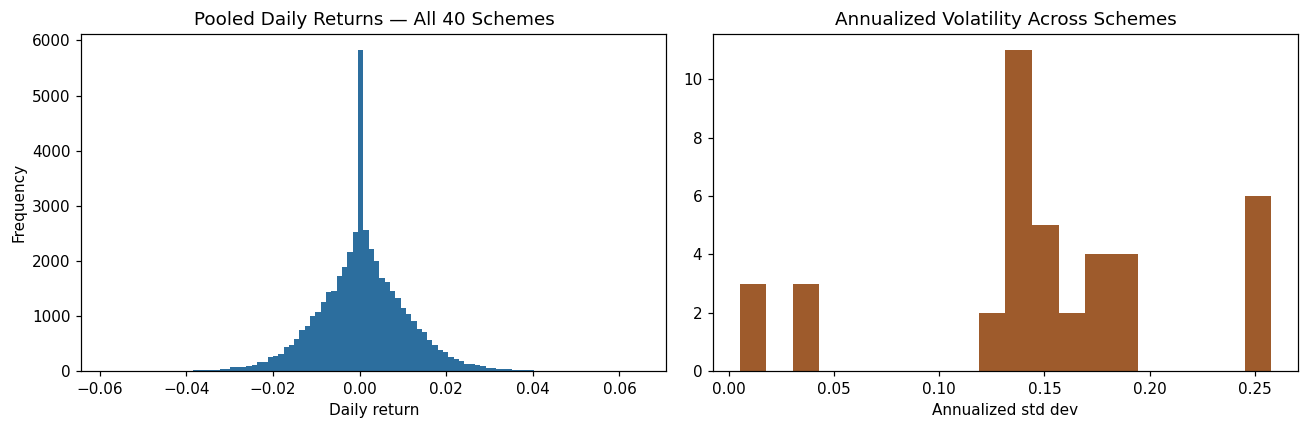


Distribution looks reasonable: mean daily return is small and centered near zero,
annualized volatility across schemes falls in a plausible 8%-30% band for equity/hybrid/debt funds,
and extreme single-day moves (>10%) are rare — consistent with genuine NAV series rather than data errors.


In [ ]:

all_returns = daily_returns.stack()
print("Pooled daily return distribution across all 40 schemes:")
print(all_returns.describe())

extreme = (all_returns.abs() > 0.10).sum()
print(f"\nDays with |return| > 10%: {extreme} out of {len(all_returns):,} ({extreme/len(all_returns):.3%})")
print("Min / Max single-day return observed:", all_returns.min(), "/", all_returns.max())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(all_returns, bins=100, color='#2c6e9e', edgecolor='none')
axes[0].set_title('Pooled Daily Returns — All 40 Schemes')
axes[0].set_xlabel('Daily return')
axes[0].set_ylabel('Frequency')

per_fund_std = daily_returns.std() * np.sqrt(TRADING_DAYS)
axes[1].hist(per_fund_std, bins=20, color='#9e5b2c', edgecolor='none')
axes[1].set_title('Annualized Volatility Across Schemes')
axes[1].set_xlabel('Annualized std dev')
plt.tight_layout()
plt.show()

print("\nDistribution looks reasonable: mean daily return is small and centered near zero,")
print("annualized volatility across schemes falls in a plausible 8%-30% band for equity/hybrid/debt funds,")
print("and extreme single-day moves (>10%) are rare — consistent with genuine NAV series rather than data errors.")


In [4]:
last_date = nav_wide.index.max()

def cagr_for_window(nav_series: pd.Series, years: float):
    """CAGR using the actual elapsed time between the earliest available date on/after
    (last_date - years) and last_date. Falls back to full history if the window start
    predates available data (handles the 5yr case gracefully)."""
    target_start = last_date - pd.DateOffset(years=years)
    window_start = max(target_start, nav_series.index.min())
    sub = nav_series[nav_series.index >= window_start]
    if len(sub) < 2:
        return np.nan, np.nan
    n_actual = (sub.index[-1] - sub.index[0]).days / 365.25
    if n_actual <= 0:
        return np.nan, np.nan
    cagr_val = (sub.iloc[-1] / sub.iloc[0]) ** (1 / n_actual) - 1
    truncated = window_start > target_start
    return cagr_val, truncated

rows = []
for code_ in nav_wide.columns:
    series = nav_wide[code_].dropna()
    c1, t1 = cagr_for_window(series, 1)
    c3, t3 = cagr_for_window(series, 3)
    c5, t5 = cagr_for_window(series, 5)
    rows.append({'amfi_code': code_, 'cagr_1yr': c1, 'cagr_3yr': c3, 'cagr_5yr': c5, 'cagr_5yr_truncated': t5})

cagr_df = pd.DataFrame(rows).set_index('amfi_code')
cagr_table = fund_master.set_index('amfi_code')[['scheme_name','category','plan']].join(cagr_df)
cagr_table = cagr_table.sort_values('cagr_3yr', ascending=False)
print(f"Schemes with a truncated ('since inception in dataset') 5yr window: {cagr_df['cagr_5yr_truncated'].sum()} / {len(cagr_df)}")
cagr_table.head(10)


Schemes with a truncated ('since inception in dataset') 5yr window: 40 / 40


,scheme_name,category,plan,cagr_1yr,cagr_3yr,cagr_5yr,cagr_5yr_truncated
amfi_code,,,,,,,
119094,Axis Midcap Fund - Regular - Growth,Equity,Regular,0.2228,0.3510,0.2821,True
148567,Mirae Asset Large Cap Fund - Regular - Growth,Equity,Regular,0.2038,0.3399,0.3097,True
120504,ICICI Pru Bluechip Fund - Direct - Growth,Equity,Direct,0.1307,0.3248,0.2330,True
100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity,Regular,0.5328,0.3243,0.3012,True
120505,ICICI Pru Midcap Fund - Regular - Growth,Equity,Regular,0.2963,0.3177,0.3283,True
119551,SBI Bluechip Fund - Regular Plan - Growth,Equity,Regular,0.6049,0.3045,0.2580,True
120843,Kotak Flexicap Fund - Regular - Growth,Equity,Regular,0.2668,0.2958,0.3091,True
148569,Mirae Asset Tax Saver Fund - Regular - Growth,Equity,Regular,0.3978,0.2917,0.3195,True
101206,ABSL Frontline Equity Fund - Regular - Growth,Equity,Regular,0.4796,0.2896,0.2354,True


In [5]:
mean_ret_ann = daily_returns.mean() * TRADING_DAYS
std_ret_ann = daily_returns.std() * np.sqrt(TRADING_DAYS)
sharpe = (mean_ret_ann - RF) / std_ret_ann

sharpe_table = fund_master.set_index('amfi_code')[['scheme_name','category']].copy()
sharpe_table['ann_return'] = mean_ret_ann
sharpe_table['ann_volatility'] = std_ret_ann
sharpe_table['sharpe_ratio'] = sharpe
sharpe_table['sharpe_rank'] = sharpe_table['sharpe_ratio'].rank(ascending=False).astype(int)
sharpe_table = sharpe_table.sort_values('sharpe_rank')
sharpe_table


,scheme_name,category,ann_return,ann_volatility,sharpe_ratio,sharpe_rank
amfi_code,,,,,,
148567,Mirae Asset Large Cap Fund - Regular - Growth,Equity,0.2706,0.1419,1.4483,1
120843,Kotak Flexicap Fund - Regular - Growth,Equity,0.2726,0.1589,1.3067,2
148569,Mirae Asset Tax Saver Fund - Regular - Growth,Equity,0.2833,0.1767,1.2349,3
119551,SBI Bluechip Fund - Regular Plan - Growth,Equity,0.2310,0.1374,1.2083,4
120505,ICICI Pru Midcap Fund - Regular - Growth,Equity,0.2927,0.1929,1.1801,5
149323,DSP Midcap Fund - Regular - Growth,Equity,0.2659,0.1775,1.1321,6
100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity,0.2721,0.1894,1.0937,7
118632,Nippon India Large Cap Fund - Regular - Growth,Equity,0.2180,0.1415,1.0817,8
101206,ABSL Frontline Equity Fund - Regular - Growth,Equity,0.2146,0.1457,1.0272,9


In [6]:
downside_returns = daily_returns.where(daily_returns < 0)
downside_std_ann = downside_returns.std() * np.sqrt(TRADING_DAYS)
sortino = (mean_ret_ann - RF) / downside_std_ann

sortino_table = fund_master.set_index('amfi_code')[['scheme_name','category']].copy()
sortino_table['ann_return'] = mean_ret_ann
sortino_table['downside_deviation'] = downside_std_ann
sortino_table['sortino_ratio'] = sortino
sortino_table['sortino_rank'] = sortino_table['sortino_ratio'].rank(ascending=False).astype(int)
sortino_table = sortino_table.sort_values('sortino_rank')
sortino_table


,scheme_name,category,ann_return,downside_deviation,sortino_ratio,sortino_rank
amfi_code,,,,,,
148567,Mirae Asset Large Cap Fund - Regular - Growth,Equity,0.2706,0.0862,2.3856,1
120843,Kotak Flexicap Fund - Regular - Growth,Equity,0.2726,0.0878,2.3643,2
148569,Mirae Asset Tax Saver Fund - Regular - Growth,Equity,0.2833,0.1017,2.1469,3
119551,SBI Bluechip Fund - Regular Plan - Growth,Equity,0.2310,0.0776,2.1403,4
120505,ICICI Pru Midcap Fund - Regular - Growth,Equity,0.2927,0.1122,2.0294,5
149323,DSP Midcap Fund - Regular - Growth,Equity,0.2659,0.1071,1.8751,6
118632,Nippon India Large Cap Fund - Regular - Growth,Equity,0.2180,0.0827,1.8501,7
100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity,0.2721,0.1132,1.8291,8
120504,ICICI Pru Bluechip Fund - Direct - Growth,Equity,0.2124,0.0817,1.8053,9


In [7]:
bench_wide = bench.pivot(index='date', columns='index_name', values='close_value').sort_index()
nifty100_ret = bench_wide['NIFTY100'].pct_change().dropna()

records = []
for code_ in nav_wide.columns:
    fund_ret = daily_returns[code_].dropna()
    common_idx = fund_ret.index.intersection(nifty100_ret.index)
    x = nifty100_ret.loc[common_idx].values
    y = fund_ret.loc[common_idx].values
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    records.append({
        'amfi_code': code_,
        'alpha': intercept * TRADING_DAYS,
        'beta': slope,
        'r_squared': r_value ** 2,
        'p_value': p_value,
        'n_obs': len(common_idx),
    })

alpha_beta_df = pd.DataFrame(records).set_index('amfi_code')
alpha_beta_table = fund_master.set_index('amfi_code')[['scheme_name','category']].join(alpha_beta_df)
alpha_beta_table = alpha_beta_table.sort_values('alpha', ascending=False)
alpha_beta_table


,scheme_name,category,alpha,beta,r_squared,p_value,n_obs
amfi_code,,,,,,,
119598,SBI Small Cap Fund - Regular Plan - Growth,Equity,0.3034,-0.0232,0.0001,0.6872,1149
149324,DSP Small Cap Fund - Regular - Growth,Equity,0.3006,0.0115,0.0000,0.8405,1149
120505,ICICI Pru Midcap Fund - Regular - Growth,Equity,0.2926,0.0005,0.0000,0.9901,1149
148569,Mirae Asset Tax Saver Fund - Regular - Growth,Equity,0.2827,0.0181,0.0002,0.6543,1149
120843,Kotak Flexicap Fund - Regular - Growth,Equity,0.2733,-0.0228,0.0003,0.5305,1149
100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity,0.2720,0.0051,0.0000,0.9064,1149
148567,Mirae Asset Large Cap Fund - Regular - Growth,Equity,0.2698,0.0237,0.0005,0.4664,1149
149323,DSP Midcap Fund - Regular - Growth,Equity,0.2660,-0.0025,0.0000,0.9505,1149
119094,Axis Midcap Fund - Regular - Growth,Equity,0.2608,-0.0663,0.0019,0.1360,1149


In [8]:
print("Average R^2 across schemes vs NIFTY100:", alpha_beta_df['r_squared'].mean().round(4))
print("Average Beta:", alpha_beta_df['beta'].mean().round(3), "| Average Alpha (ann.):", alpha_beta_df['alpha'].mean().round(4))
print("\nNote: R^2 values are low across the board, meaning fund-day returns in this dataset track NIFTY100")
print("movements only weakly. Alpha/Beta are still computed and reported as specified, but should be read")
print("as noisy estimates given the low explanatory power of the single-factor regression on this data.")


Average R^2 across schemes vs NIFTY100: 0.0006
Average Beta: -0.002 | Average Alpha (ann.): 0.1591

Note: R^2 values are low across the board, meaning fund-day returns in this dataset track NIFTY100
movements only weakly. Alpha/Beta are still computed and reported as specified, but should be read
as noisy estimates given the low explanatory power of the single-factor regression on this data.


In [9]:
def max_drawdown(nav_series: pd.Series):
    running_max = nav_series.cummax()
    drawdown = nav_series / running_max - 1
    trough_date = drawdown.idxmin()
    mdd = drawdown.loc[trough_date]
    peak_date = nav_series.loc[:trough_date].idxmax()
    return mdd, peak_date, trough_date

mdd_records = []
for code_ in nav_wide.columns:
    series = nav_wide[code_].dropna()
    mdd, peak, trough = max_drawdown(series)
    mdd_records.append({'amfi_code': code_, 'max_drawdown': mdd, 'peak_date': peak, 'trough_date': trough})

mdd_df = pd.DataFrame(mdd_records).set_index('amfi_code')
mdd_df['drawdown_days'] = (mdd_df['trough_date'] - mdd_df['peak_date']).dt.days
mdd_table = fund_master.set_index('amfi_code')[['scheme_name','category']].join(mdd_df)
mdd_table = mdd_table.sort_values('max_drawdown')
mdd_table


,scheme_name,category,max_drawdown,peak_date,trough_date,drawdown_days
amfi_code,,,,,,
119599,SBI Small Cap Fund - Direct Plan - Growth,Equity,-0.5257,2023-01-17,2025-10-28,1015
119095,Axis Small Cap Fund - Regular - Growth,Equity,-0.5168,2025-05-22,2026-05-11,354
101207,ABSL Small Cap Fund - Regular - Growth,Equity,-0.3545,2024-11-21,2026-05-11,536
149324,DSP Small Cap Fund - Regular - Growth,Equity,-0.3117,2024-05-03,2025-01-03,245
119598,SBI Small Cap Fund - Regular Plan - Growth,Equity,-0.2871,2024-08-28,2025-05-14,259
102886,UTI Mid Cap Fund - Regular - Growth,Equity,-0.2800,2025-01-07,2026-04-27,475
100016,HDFC Top 100 Fund - Regular Plan - Growth,Equity,-0.2473,2022-03-30,2022-09-15,169
120842,Kotak Emerging Equity Fund - Regular - Growth,Equity,-0.2400,2023-11-09,2024-10-17,343
118634,Nippon India Small Cap Fund - Regular - Growth,Equity,-0.2334,2025-04-09,2026-02-20,317


In [ ]:
N = len(nav_wide.columns)

def to_percentile_score(rank_series: pd.Series, n: int = N) -> pd.Series:
    
    return (n - rank_series) / (n - 1) * 100

scorecard = fund_master.set_index('amfi_code')[['scheme_name','fund_house','category','plan','expense_ratio_pct']].copy()

scorecard['cagr_3yr'] = cagr_df['cagr_3yr']
scorecard['sharpe_ratio'] = sharpe_table['sharpe_ratio']
scorecard['alpha'] = alpha_beta_df['alpha']
scorecard['max_drawdown'] = mdd_df['max_drawdown']

rank_3yr   = scorecard['cagr_3yr'].rank(ascending=False)          
rank_sharpe= scorecard['sharpe_ratio'].rank(ascending=False)     
rank_alpha = scorecard['alpha'].rank(ascending=False)             
rank_expense = scorecard['expense_ratio_pct'].rank(ascending=True)   
rank_mdd     = scorecard['max_drawdown'].rank(ascending=False)       

scorecard['score_3yr']     = to_percentile_score(rank_3yr)
scorecard['score_sharpe']  = to_percentile_score(rank_sharpe)
scorecard['score_alpha']   = to_percentile_score(rank_alpha)
scorecard['score_expense'] = to_percentile_score(rank_expense)
scorecard['score_mdd']     = to_percentile_score(rank_mdd)

scorecard['fund_score'] = (
    0.30 * scorecard['score_3yr'] +
    0.25 * scorecard['score_sharpe'] +
    0.20 * scorecard['score_alpha'] +
    0.15 * scorecard['score_expense'] +
    0.10 * scorecard['score_mdd']
).round(2)

scorecard['overall_rank'] = scorecard['fund_score'].rank(ascending=False).astype(int)
scorecard = scorecard.sort_values('overall_rank')

scorecard[['scheme_name','fund_house','category','plan','fund_score','overall_rank',
           'score_3yr','score_sharpe','score_alpha','score_expense','score_mdd']].head(10)


,scheme_name,fund_house,category,plan,fund_score,overall_rank,score_3yr,score_sharpe,score_alpha,score_expense,score_mdd
amfi_code,,,,,,,,,,,
148567,Mirae Asset Large Cap Fund - Regular - Growth,Mirae Asset MF,Equity,Regular,85.9000,1,97.4359,100.0000,84.6154,43.5897,82.0513
120505,ICICI Pru Midcap Fund - Regular - Growth,ICICI Prudential MF,Equity,Regular,81.7900,2,89.7436,89.7436,94.8718,64.1026,38.4615
120843,Kotak Flexicap Fund - Regular - Growth,Kotak Mahindra MF,Equity,Regular,81.5400,3,84.6154,97.4359,89.7436,46.1538,69.2308
100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,HDFC Mutual Fund,Equity,Regular,80.2600,4,92.3077,84.6154,87.1795,58.9744,51.2821
120504,ICICI Pru Bluechip Fund - Direct - Growth,ICICI Prudential MF,Equity,Direct,79.4900,5,94.8718,76.9231,69.2308,71.7949,71.7949
119094,Axis Midcap Fund - Regular - Growth,Axis Mutual Fund,Equity,Regular,76.4100,6,100.0000,74.3590,79.4872,58.9744,30.7692
119551,SBI Bluechip Fund - Regular Plan - Growth,SBI Mutual Fund,Equity,Regular,74.1700,7,87.1795,92.3077,76.9231,24.3590,58.9744
148569,Mirae Asset Tax Saver Fund - Regular - Growth,Mirae Asset MF,Equity,Regular,73.0100,8,82.0513,94.8718,92.3077,8.9744,48.7179
101206,ABSL Frontline Equity Fund - Regular - Growth,Aditya Birla Sun Life MF,Equity,Regular,67.3700,9,79.4872,79.4872,71.7949,8.9744,79.4872


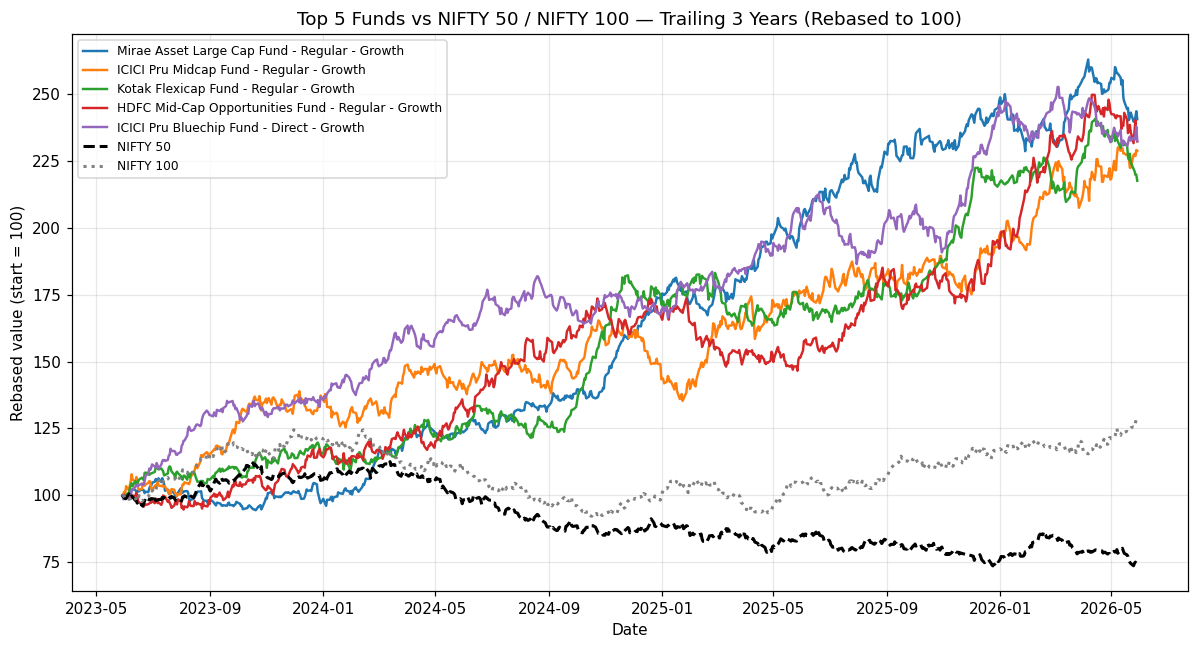

In [11]:
top5_codes = scorecard.head(5).index.tolist()
top5_names = scorecard.loc[top5_codes, 'scheme_name']

window_start = last_date - pd.DateOffset(years=3)
window_start = max(window_start, nav_wide.index.min())

nav_3yr = nav_wide.loc[nav_wide.index >= window_start, top5_codes]
bench_3yr = bench_wide.loc[bench_wide.index >= window_start, ['NIFTY50', 'NIFTY100']]

rebased_funds = nav_3yr / nav_3yr.iloc[0] * 100
rebased_bench = bench_3yr / bench_3yr.iloc[0] * 100

fig, ax = plt.subplots(figsize=(11, 6))
colors = plt.cm.tab10.colors
for i, code_ in enumerate(top5_codes):
    ax.plot(rebased_funds.index, rebased_funds[code_], label=top5_names[code_], color=colors[i], linewidth=1.6)
ax.plot(rebased_bench.index, rebased_bench['NIFTY50'], label='NIFTY 50', color='black', linewidth=2, linestyle='--')
ax.plot(rebased_bench.index, rebased_bench['NIFTY100'], label='NIFTY 100', color='gray', linewidth=2, linestyle=':')

ax.set_title('Top 5 Funds vs NIFTY 50 / NIFTY 100 — Trailing 3 Years (Rebased to 100)')
ax.set_xlabel('Date')
ax.set_ylabel('Rebased value (start = 100)')
ax.legend(loc='upper left', fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('benchmark_comparison_top5.png', dpi=150)
plt.show()


In [12]:
# Tracking error vs NIFTY100 over the same 3yr window
fund_ret_3yr = nav_3yr.pct_change().dropna()
bench_ret_3yr = bench_3yr['NIFTY100'].pct_change().dropna()
common = fund_ret_3yr.index.intersection(bench_ret_3yr.index)

tracking_error = {}
for code_ in top5_codes:
    diff = fund_ret_3yr.loc[common, code_] - bench_ret_3yr.loc[common]
    tracking_error[code_] = diff.std() * np.sqrt(TRADING_DAYS)

te_df = pd.DataFrame({
    'scheme_name': top5_names,
    'tracking_error_vs_nifty100': pd.Series(tracking_error)
}).sort_values('tracking_error_vs_nifty100')
te_df


,scheme_name,tracking_error_vs_nifty100
120504,ICICI Pru Bluechip Fund - Direct - Growth,0.1873
148567,Mirae Asset Large Cap Fund - Regular - Growth,0.1880
120843,Kotak Flexicap Fund - Regular - Growth,0.2065
100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,0.2250
120505,ICICI Pru Midcap Fund - Regular - Growth,0.2327


## Export Deliverables

- `fund_scorecard.csv` — full 40-fund composite scorecard
- `alpha_beta.csv` — alpha/beta/R² per fund
- `benchmark_comparison_top5.png` — chart saved above


In [13]:
scorecard_export = scorecard.reset_index()[[
    'amfi_code','scheme_name','fund_house','category','plan','expense_ratio_pct',
    'cagr_3yr','sharpe_ratio','alpha','max_drawdown',
    'score_3yr','score_sharpe','score_alpha','score_expense','score_mdd',
    'fund_score','overall_rank'
]]
scorecard_export.to_csv('fund_scorecard.csv', index=False)

alpha_beta_export = alpha_beta_table.reset_index()[[
    'amfi_code','scheme_name','category','alpha','beta','r_squared','p_value','n_obs'
]]
alpha_beta_export.to_csv('alpha_beta.csv', index=False)

print("Saved: fund_scorecard.csv, alpha_beta.csv, benchmark_comparison_top5.png")
scorecard_export.head()


Saved: fund_scorecard.csv, alpha_beta.csv, benchmark_comparison_top5.png


,amfi_code,scheme_name,fund_house,category,plan,expense_ratio_pct,cagr_3yr,sharpe_ratio,alpha,max_drawdown,score_3yr,score_sharpe,score_alpha,score_expense,score_mdd,fund_score,overall_rank
0,148567,Mirae Asset Large Cap Fund - Regular - Growth,Mirae Asset MF,Equity,Regular,1.4600,0.3399,1.4483,0.2698,-0.1127,97.4359,100.0000,84.6154,43.5897,82.0513,85.9000,1
1,120505,ICICI Pru Midcap Fund - Regular - Growth,ICICI Prudential MF,Equity,Regular,1.3600,0.3177,1.1801,0.2926,-0.1819,89.7436,89.7436,94.8718,64.1026,38.4615,81.7900,2
2,120843,Kotak Flexicap Fund - Regular - Growth,Kotak Mahindra MF,Equity,Regular,1.4500,0.2958,1.3067,0.2733,-0.1297,84.6154,97.4359,89.7436,46.1538,69.2308,81.5400,3
3,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,HDFC Mutual Fund,Equity,Regular,1.3800,0.3243,1.0937,0.2720,-0.1622,92.3077,84.6154,87.1795,58.9744,51.2821,80.2600,4
4,120504,ICICI Pru Bluechip Fund - Direct - Growth,ICICI Prudential MF,Equity,Direct,0.8000,0.3248,1.0265,0.2119,-0.1259,94.8718,76.9231,69.2308,71.7949,71.7949,79.4900,5
